A self-contained notebook that learns to correct coarse simulations of one SDE family, with every helper function and model definition written directly in the notebook.

In this notebook we will look at the Ornstein–Uhlenbeck (OU) as the example: it is one-dimensional, quick to simulate, and simple enough that the reader can focus on how FMint works. We can vary its parameters while staying within the same problem family:

$$
dX_t = \theta(\mu-X_t)\,dt + \sigma\,dW_t.
$$

The goal of the notebook is to learn

$$
\widehat{X}_{\mathrm{fine}}
=
X_{\mathrm{coarse}}
+
\widehat{\text{correction}},
$$

using a few demonstration trajectories from the same parameter setting as the query trajectory.

We will use a small, caption-free model trained from scratch.

# Learning to correct coarse SDE simulations with FMint

Stochastic differential equations (SDEs) describe systems influenced by both deterministic dynamics and random fluctuations. Simulating these systems with small time steps can be computationally expensive. Larger time steps reduce that cost, but introduce numerical error. In this notebook, we explore whether a model can learn to correct that error using a few examples.

We focus on the Ornstein–Uhlenbeck process, a simple model of a noisy system that tends to return toward an equilibrium:

$$
dX_t = \theta(\mu-X_t)\,dt + \sigma\,dW_t,
$$

where $\mu$ is the equilibrium value, $\theta>0$ controls the rate of return toward equilibrium, $\sigma$ controls the noise strength, and $W_t$ is standard Brownian motion. We vary these parameters to create different instances of the same SDE family.

For each instance, we generate a fine reference trajectory using small time steps and a coarse trajectory using larger time steps. Both simulations use the same underlying Brownian path: each coarse noise increment is the sum of the corresponding fine increments. This coupling lets us study numerical error without confusing it with differences between random realizations. The fine trajectory serves as our numerical reference, rather than an exact solution.

At the coarse observation times, we define the correction as

$$
c(t)=X_{\mathrm{fine}}(t)-X_{\mathrm{coarse}}(t).
$$

FMint learns to predict this correction. Its input contains a few demonstrations—coarse trajectories paired with their known corrections—and a new query coarse trajectory. The demonstrations and query share the same SDE parameters but have independently sampled initial conditions and noise realizations. The query’s reference trajectory is withheld from the model and used only for training or evaluation.

The model uses the demonstrations to infer how to correct the query, producing

$$
\widehat{X}_{\mathrm{fine}}(t)
=
X_{\mathrm{coarse}}(t)+\widehat{c}(t).
$$

We will build the entire workflow in this notebook:
1. Simulate coupled fine and coarse OU trajectories.
2. Organize them into demonstration–query examples.
3. Define and train a small attention-based FMint model.
4. Predict corrections for held-out OU parameter settings.
5. Plot the resulting trajectories and compare their errors.
The final experiment asks a concrete question: does the learned correction bring a coarse trajectory closer to the fine reference on problems the model has not seen during training?

## Imports and experiment configuration

In [2]:
import torch
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)

PyTorch version: 2.5.1


In [3]:
# Reproducibility
seed = 42
torch.manual_seed(seed)

# Ornstein–Uhlenbeck parameter ranges
theta_range = (0.1, 0.5)
mu_range = (1.0, 5.0)
sigma_range = (0.1, 0.5)
initial_range = (0.0, 6.0)

# Simulation
# Time steps from the paper's OU experiment
dt_fine = 0.001
fine_steps_per_coarse = 100
dt_coarse = dt_fine * fine_steps_per_coarse  # 0.01

# Choose the trajectory length
coarse_steps = 50
fine_steps = coarse_steps * fine_steps_per_coarse  # 5000

# Derive the horizon from the steps
horizon = coarse_steps * dt_coarse  # 5.0

# Dataset
train_parameters = 100
val_parameters = 20
test_parameters = 20
trajectories_per_parameter = 12
num_demos = 3

# Model
model_dim = 64
num_heads = 4
num_layers = 2
feedforward_dim = 128

# Training
batch_size = 16
training_steps = 2000
learning_rate = 1e-3

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Device:", device)
print(f"Coarse time step: {dt_coarse:.4f}")
print(f"Fine time step:   {dt_fine:.4f}")

Device: mps
Coarse time step: 0.1000
Fine time step:   0.0010


## Define the OU System and Numerical SOlver
We can define this in three small cells: the OU update, Brownian noise generation, and the simulation loop. 

### Define the drift and Euler–Maruyama step

The OU drift is $\theta(\mu-x)$. It pushes the state toward $\mu$: positive when $x<\mu$, negative when $x>\mu$.

In [4]:
def ou_drift(x, theta, mu):
    return theta * (mu - x)


def euler_maruyama_step(x, theta, mu, sigma, dt, dW):
    drift = ou_drift(x, theta, mu)
    return x + drift * dt + sigma * dW

The update has three parts:
- x: the current state.
- drift * dt: the deterministic change over the time step.
- sigma * dW: the random change.

Here, dW is already a Brownian increment, so we do not multiply it by sqrt(dt) again.

### Sample Brownian increments
For Brownian motion,
$$
\Delta W_n \sim \mathcal{N}(0,\Delta t).
$$
Its standard deviation is therefore $\sqrt{\Delta t}$.

In [5]:
def sample_brownian_increments(n_steps, dt, n_paths=1, device="cpu"):
    noise = torch.randn(n_paths, n_steps, device=device)
    return noise * dt**0.5

torch.randn samples independent standard normal values. Multiplying by dt**0.5 gives the required variance.
The output has shape:

(number of trajectories, number of time steps)

Sampling the noise separately from the solver will let us reuse it to generate coupled fine and coarse trajectories later.

### Simulate Trajectories

The solver accepts the initial state, OU parameters, time step, and sampled increments.

In [6]:
def simulate_ou(x0, theta, mu, sigma, dt, dW):
    """
    dW: shape (n_paths, n_steps)

    Returns trajectories with shape (n_paths, n_steps + 1),
    including the initial state.
    """
    n_paths, n_steps = dW.shape

    # Match the noise tensor's device and precision.
    x = torch.as_tensor(x0, dtype=dW.dtype, device=dW.device)
    theta = torch.as_tensor(theta, dtype=dW.dtype, device=dW.device)
    mu = torch.as_tensor(mu, dtype=dW.dtype, device=dW.device)
    sigma = torch.as_tensor(sigma, dtype=dW.dtype, device=dW.device)

    # A scalar initial state is shared by all paths.
    # A vector of length n_paths gives each path its own initial state.
    x = x.expand(n_paths).clone()

    states = [x]

    for n in range(n_steps):
        x = euler_maruyama_step(
            x, theta, mu, sigma, dt, dW[:, n]
        )
        states.append(x)

    return torch.stack(states, dim=1)

In [7]:
# Generate the fine Brownian increments.
dW_fine = sample_brownian_increments(
    n_steps=fine_steps,
    dt=dt_fine,
    device=device,
)

# Sum each group of fine increments into one coarse increment.
dW_coarse = dW_fine.reshape(
    1, coarse_steps, fine_steps_per_coarse
).sum(dim=-1)

In [8]:
# theta = 1.9 / dt_coarse
theta = 0.1
mu = 1.0
sigma = 0.3
x0 = 0.0

fine_trajectory = simulate_ou(
    x0, theta, mu, sigma, dt_fine, dW_fine
)

coarse_trajectory = simulate_ou(
    x0, theta, mu, sigma, dt_coarse, dW_coarse
)

# Sample the fine trajectory at matching coarse times.
fine_at_coarse_times = fine_trajectory[:, ::fine_steps_per_coarse]

# This difference will become FMint's correction target.
correction = fine_at_coarse_times - coarse_trajectory

In [9]:
dt_coarse

0.1

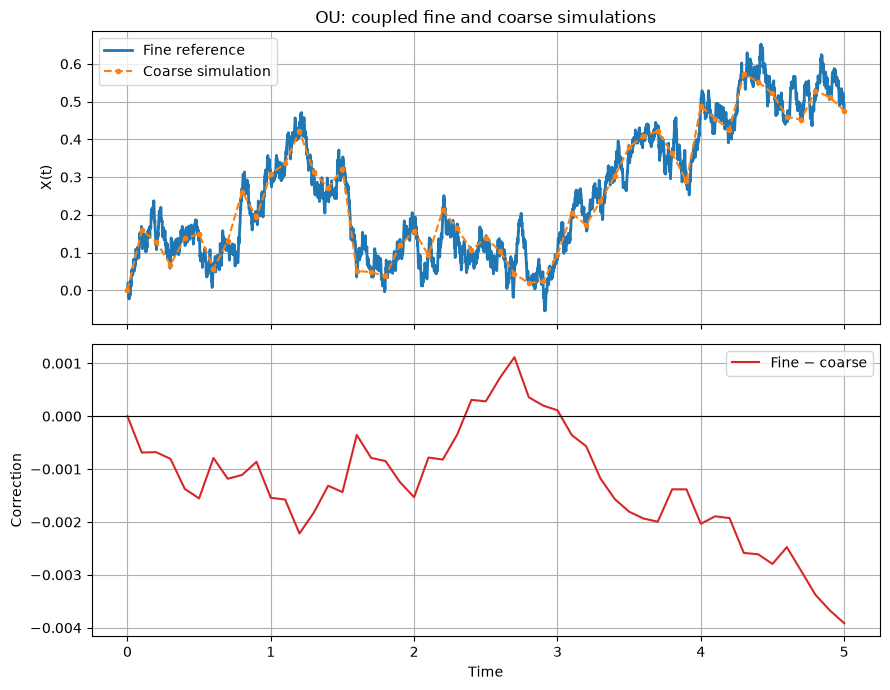

Mean absolute difference: 0.001395
Maximum absolute difference: 0.003914


In [10]:
fine_times = torch.arange(fine_steps + 1) * dt_fine
coarse_times = torch.arange(coarse_steps + 1) * dt_coarse

# Move plotting data to the CPU.
fine_values = fine_trajectory[0].detach().cpu().numpy()
coarse_values = coarse_trajectory[0].detach().cpu().numpy()
correction_values = correction[0].detach().cpu().numpy()

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

axes[0].plot(
    fine_times.numpy(), fine_values,
    label="Fine reference", linewidth=2,
)
axes[0].plot(
    coarse_times.numpy(), coarse_values,
    "o--", label="Coarse simulation", markersize=3,
)
axes[0].set_ylabel("X(t)")
axes[0].set_title("OU: coupled fine and coarse simulations")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    coarse_times.numpy(), correction_values,
    color="tab:red", label="Fine − coarse",
)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Correction")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f"Mean absolute difference: {correction.abs().mean().item():.6f}")
print(f"Maximum absolute difference: {correction.abs().max().item():.6f}")

### Making the Dataset
#### Generate a group of trajectories

Start with one fixed parameter triple—for example, your chosen theta, mu, and sigma—and generate 12 trajectories.

Each trajectory should have:
- Its own Brownian noise realization.
- Its own initial condition, if you want to vary initial conditions.
- A fine and coarse simulation coupled through the same Brownian path.

The fine/coarse pair shares noise; different trajectories have independent noise.
When aggregating fine increments into coarse increments, preserve the path dimension: reshape into number of paths × coarse steps × fine steps per coarse step, then sum over the last dimension.



In [11]:
# theta = 1.9 / dt_coarse
theta = 0.1
mu = 1.0
sigma = 0.3
x0 = 0.0

n_paths = 12
num_demos = 3

fine_steps = coarse_steps * fine_steps_per_coarse

In [12]:
dW_fine = sample_brownian_increments(
    n_steps=fine_steps,
    dt=dt_fine,
    n_paths=n_paths,
    device=device,
)

dW_coarse = dW_fine.reshape(
    n_paths,
    coarse_steps,
    fine_steps_per_coarse,
).sum(dim=-1)

print("Fine increments:", dW_fine.shape)
print("Coarse increments:", dW_coarse.shape)

Fine increments: torch.Size([12, 5000])
Coarse increments: torch.Size([12, 50])


In [13]:
fine_trajectories = simulate_ou(
    x0, theta, mu, sigma, dt_fine, dW_fine
)

coarse_trajectories = simulate_ou(
    x0, theta, mu, sigma, dt_coarse, dW_coarse
)

fine_aligned = fine_trajectories[:, ::fine_steps_per_coarse]
corrections = fine_aligned - coarse_trajectories

# Use observations after the initial state.
# Each time is paired with the increment over the preceding interval.
times = (
    torch.arange(
        1,
        coarse_steps + 1,
        device=dW_fine.device,
        dtype=dW_fine.dtype,
    )
    * dt_coarse
)

coarse_values = coarse_trajectories[:, 1:]
fine_values = fine_aligned[:, 1:]
correction_values = corrections[:, 1:]

# Input features: [time, Brownian increment, coarse state].
inputs = torch.stack(
    [
        times.unsqueeze(0).expand(n_paths, -1),
        dW_coarse,
        coarse_values,
    ],
    dim=-1,
)

group = {
    "parameters": (theta, mu, sigma),
    "times": times,
    "inputs": inputs,
    "corrections": correction_values.unsqueeze(-1),
    "fine": fine_values.unsqueeze(-1),
}

print("Inputs:", group["inputs"].shape)
print("Corrections:", group["corrections"].shape)

Inputs: torch.Size([12, 50, 3])
Corrections: torch.Size([12, 50, 1])


In [14]:
def select_trajectories(n_paths, num_demos, device):
    if n_paths < num_demos + 1:
        raise ValueError("Need enough paths for demonstrations and a query.")

    indices = torch.randperm(n_paths, device=device)

    demo_indices = indices[:num_demos]
    query_index = indices[num_demos].item()

    return demo_indices, query_index


demo_indices, query_index = select_trajectories(
    n_paths=n_paths,
    num_demos=num_demos,
    device=group["inputs"].device,
)

print("Demonstration paths:", demo_indices.cpu().tolist())
print("Query path:", query_index)

Demonstration paths: [4, 11, 10]
Query path: 7


In [15]:
def build_example(group, demo_indices, query_index):
    model_inputs = {
        "demo_inputs": group["inputs"][demo_indices],
        "demo_corrections": group["corrections"][demo_indices],
        "query_inputs": group["inputs"][query_index],
    }

    target = group["corrections"][query_index]

    return model_inputs, target


model_inputs, target = build_example(
    group, demo_indices, query_index
)

for name, tensor in model_inputs.items():
    print(name, tuple(tensor.shape))

print("Query target:", tuple(target.shape))

demo_inputs (3, 50, 3)
demo_corrections (3, 50, 1)
query_inputs (50, 3)
Query target: (50, 1)


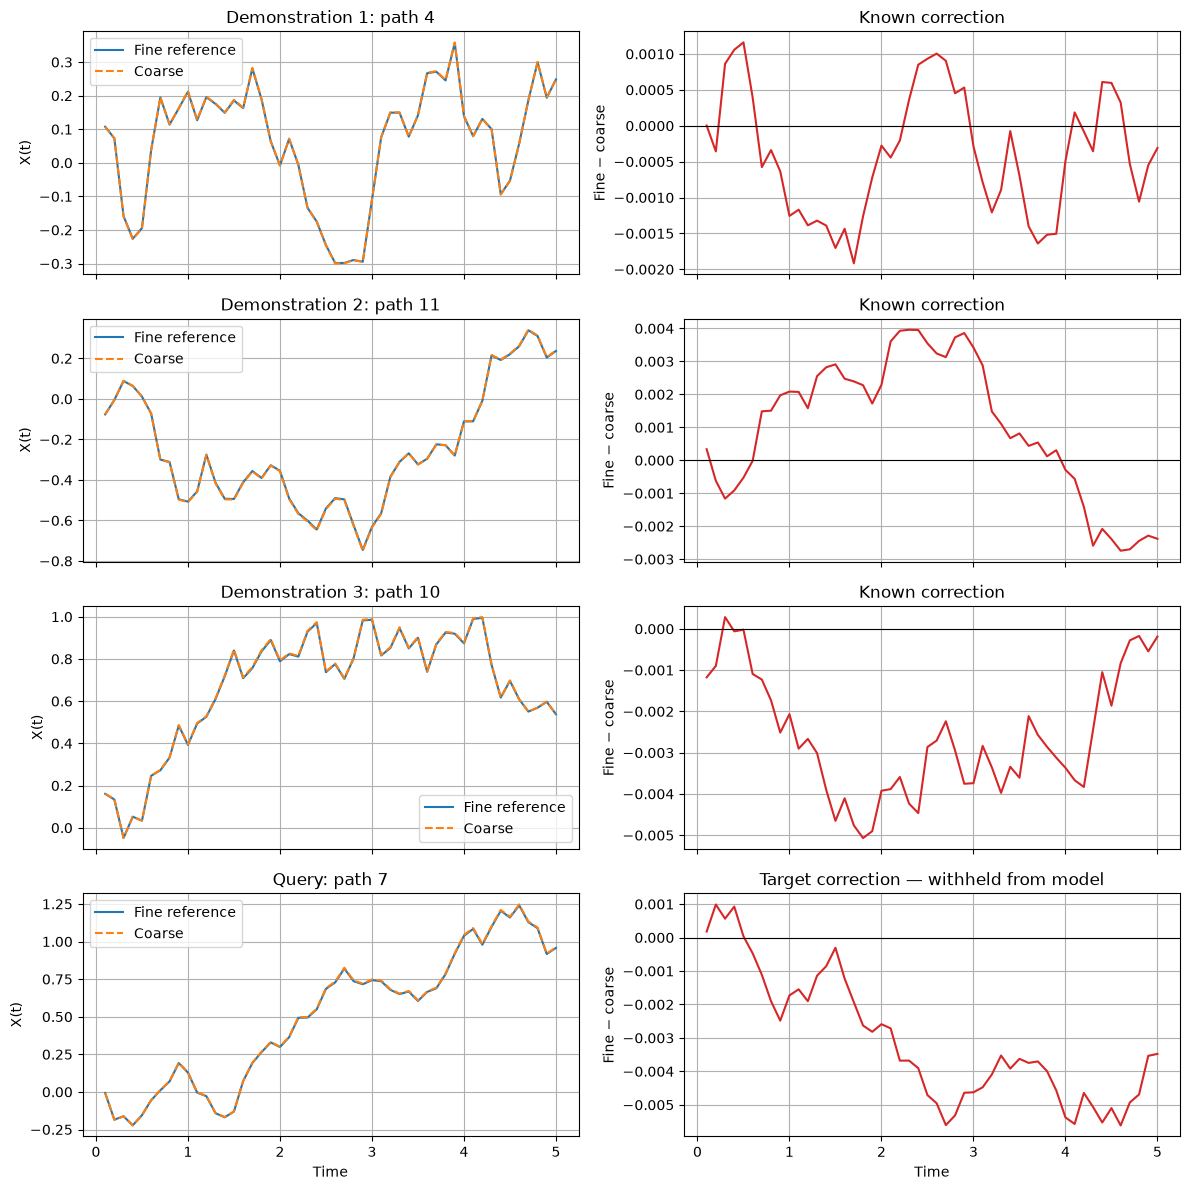

In [16]:
selected_indices = demo_indices.cpu().tolist() + [query_index]
plot_times = group["times"].detach().cpu().numpy()

fig, axes = plt.subplots(
    num_demos + 1,
    2,
    figsize=(12, 3 * (num_demos + 1)),
    sharex=True,
)

for row, path_index in enumerate(selected_indices):
    role = (
        f"Demonstration {row + 1}"
        if row < num_demos
        else "Query"
    )

    coarse = (
        group["inputs"][path_index, :, 2]
        .detach().cpu().numpy()
    )
    fine = (
        group["fine"][path_index, :, 0]
        .detach().cpu().numpy()
    )
    correction = (
        group["corrections"][path_index, :, 0]
        .detach().cpu().numpy()
    )

    axes[row, 0].plot(plot_times, fine, label="Fine reference")
    axes[row, 0].plot(plot_times, coarse, "--", label="Coarse")
    axes[row, 0].set_title(f"{role}: path {path_index}")
    axes[row, 0].set_ylabel("X(t)")
    axes[row, 0].legend()

    axes[row, 1].plot(
        plot_times, correction, color="tab:red"
    )
    axes[row, 1].axhline(0, color="black", linewidth=0.8)
    axes[row, 1].set_title(
        "Known correction" if row < num_demos
        else "Target correction — withheld from model"
    )
    axes[row, 1].set_ylabel("Fine − coarse")

    axes[row, 0].grid(True)
    axes[row, 1].grid(True)

axes[-1, 0].set_xlabel("Time")
axes[-1, 1].set_xlabel("Time")

plt.tight_layout()
plt.show()

#### Generate multiple training examples
Each example randomly chooses distinct demonstration and query trajectories from the group.

In [17]:
def build_training_examples(group, num_examples, num_demos):
    n_paths = group["inputs"].shape[0]

    input_lists = {
        "demo_inputs": [],
        "demo_corrections": [],
        "query_inputs": [],
    }
    targets = []

    for _ in range(num_examples):
        demo_indices, query_index = select_trajectories(
            n_paths=n_paths,
            num_demos=num_demos,
            device=group["inputs"].device,
        )

        model_inputs, target = build_example(
            group, demo_indices, query_index
        )

        for name in input_lists:
            input_lists[name].append(model_inputs[name])

        targets.append(target)

    training_inputs = {
        name: torch.stack(values)
        for name, values in input_lists.items()
    }
    training_targets = torch.stack(targets)

    return training_inputs, training_targets

#### Building the training tensors

In [18]:
num_examples = 256

training_inputs, training_targets = build_training_examples(
    group=group,
    num_examples=num_examples,
    num_demos=num_demos,
)

for name, tensor in training_inputs.items():
    print(name, tuple(tensor.shape))

print("training_targets", tuple(training_targets.shape))

demo_inputs (256, 3, 50, 3)
demo_corrections (256, 3, 50, 1)
query_inputs (256, 50, 3)
training_targets (256, 50, 1)


#### Select a batch for training

In [19]:
batch_size = 16

batch_indices = torch.randperm(
    num_examples,
    device=training_targets.device,
)[:batch_size]

batch_inputs = {
    name: tensor[batch_indices]
    for name, tensor in training_inputs.items()
}
batch_targets = training_targets[batch_indices]

print("Query batch:", batch_inputs["query_inputs"].shape)
print("Target batch:", batch_targets.shape)

Query batch: torch.Size([16, 50, 3])
Target batch: torch.Size([16, 50, 1])


#### Sample Parameters and Split them before generating trajectories

In [20]:
seed = 42

# theta_range = (1.2 / dt_coarse, 1.9 / dt_coarse) # change to (0.1, 0.5) for testing
theta_range = (0.1, 0.5)
mu_range = (0.5, 2.0)
sigma_range = (20.0, 80.0)
initial_range = (5.0, 15.0)

n_train_parameters = 100
n_val_parameters = 20
n_test_parameters = 20

n_parameters = (
    n_train_parameters
    + n_val_parameters
    + n_test_parameters
)

parameter_rng = torch.Generator().manual_seed(seed)


def sample_uniform(bounds, count, generator):
    low, high = bounds
    return low + (high - low) * torch.rand(
        count, generator=generator
    )


all_parameters = torch.stack(
    [
        sample_uniform(theta_range, n_parameters, parameter_rng),
        sample_uniform(mu_range, n_parameters, parameter_rng),
        sample_uniform(sigma_range, n_parameters, parameter_rng),
    ],
    dim=-1,
)

# Ensure the sampled parameter triples are distinct.
assert torch.unique(all_parameters, dim=0).shape[0] == n_parameters

order = torch.randperm(n_parameters, generator=parameter_rng)

train_end = n_train_parameters
val_end = train_end + n_val_parameters

train_parameters = all_parameters[order[:train_end]]
val_parameters = all_parameters[order[train_end:val_end]]
test_parameters = all_parameters[order[val_end:]]

print("Training parameter sets:", len(train_parameters))
print("Validation parameter sets:", len(val_parameters))
print("Test parameter sets:", len(test_parameters))

Training parameter sets: 100
Validation parameter sets: 20
Test parameter sets: 20


In [21]:
def build_training_examples(
    parameter_sets,
    examples_per_parameter=8,
    n_paths=12,
    num_demos=3,
    seed=42,
):
    assert n_paths >= num_demos + 1
    assert examples_per_parameter >= 1

    generator = torch.Generator().manual_seed(seed)
    fine_steps = coarse_steps * fine_steps_per_coarse

    times = (
        torch.arange(1, coarse_steps + 1, dtype=torch.float32)
        * dt_coarse
    )

    collected_inputs = {
        "demo_inputs": [],
        "demo_corrections": [],
        "query_inputs": [],
    }
    collected_targets = []
    collected_parameters = []

    for parameters in parameter_sets:
        theta, mu, sigma = parameters.tolist()

        # Independent initial conditions within this parameter setting.
        initial_states = sample_uniform(
            initial_range, n_paths, generator
        )

        # Coupled Brownian paths.
        dW_fine = torch.randn(
            n_paths, fine_steps, generator=generator
        ) * dt_fine**0.5

        dW_coarse = dW_fine.reshape(
            n_paths, coarse_steps, fine_steps_per_coarse
        ).sum(dim=-1)

        fine = simulate_ou(
            initial_states, theta, mu, sigma, dt_fine, dW_fine
        )
        coarse = simulate_ou(
            initial_states, theta, mu, sigma, dt_coarse, dW_coarse
        )

        # Exclude the initial state; align all post-step observations.
        fine_aligned = fine[:, fine_steps_per_coarse::fine_steps_per_coarse]
        coarse_values = coarse[:, 1:]

        corrections = (fine_aligned - coarse_values).unsqueeze(-1)

        inputs = torch.stack(
            [
                times.unsqueeze(0).expand(n_paths, -1),
                dW_coarse,
                coarse_values,
            ],
            dim=-1,
        )

        for _ in range(examples_per_parameter):
            indices = torch.randperm(n_paths, generator=generator)
            demos = indices[:num_demos]
            query = indices[num_demos]

            collected_inputs["demo_inputs"].append(inputs[demos])
            collected_inputs["demo_corrections"].append(
                corrections[demos]
            )
            collected_inputs["query_inputs"].append(inputs[query])

            collected_targets.append(corrections[query])
            collected_parameters.append(parameters)

    return {
        "inputs": {
            name: torch.stack(values)
            for name, values in collected_inputs.items()
        },
        "targets": torch.stack(collected_targets),
        "parameters": torch.stack(collected_parameters),
    }

In [22]:
num_demos = 3

train_data = build_training_examples(
    train_parameters, num_demos=num_demos, seed=seed + 1
)
val_data = build_training_examples(
    val_parameters, num_demos=num_demos, seed=seed + 2
)
test_data = build_training_examples(
    test_parameters, num_demos=num_demos, seed=seed + 3
)

for name, data in [
    ("Train", train_data),
    ("Validation", val_data),
    ("Test", test_data),
]:
    print(name, "examples:", len(data["targets"]))

Train examples: 800
Validation examples: 160
Test examples: 160


#### Define Token Layout and Attention Mask

Naming convention used:
| Utility name	| Our notation | Meaning |
|---|---|---|
| cond	| C	| Coarse trajectory condition|
| qoi_kv| E	| Coordinates plus known correction|
| qoi_k	| Q	| Coordinates plus a zero placeholder|

We’ll use three token types:

| Type | Features | Purpose |
|---|---|---|
| Condition, `C` | time, noise increment, coarse state | Describe a trajectory |
| Correction, `E` | time, noise increment, known correction | Supply a demonstration answer |
| Prediction, `Q` | time, noise increment, zero | Request a correction |

With three demonstrations, the sequence is:

C1 E1 | C2 E2 Q2 | C3 E3 Q3 | C4 Q4

Q2 predicts using one earlier demonstration, Q3 uses two, and Q4 is the final query using three. There is no prediction block for the first demonstration in this caption-free version.
The mask must prevent indirect leakage too: condition tokens cannot read their own correction and then pass it to prediction tokens.

In [23]:
# Taken from models_utils_pytorch.py
def build_diag_block(cond_len, qoi_kv_len, qoi_k_len, compact=True):
    """Return allowed attention connections within one example."""
    total = cond_len + qoi_kv_len + qoi_k_len
    allowed = torch.zeros(total, total, dtype=torch.bool)

    correction_start = cond_len
    prediction_start = cond_len + qoi_kv_len

    # All tokens can read their own condition.
    allowed[:, :cond_len] = True

    # Known-correction tokens can read their own correction block.
    if compact:
        allowed[
            correction_start:prediction_start,
            correction_start:prediction_start,
        ] = True
    else:
        allowed[
            correction_start:prediction_start,
            correction_start:,
        ] = True

    # Prediction tokens can read themselves, but not one another.
    allowed[prediction_start:, prediction_start:] = torch.eye(
        qoi_k_len, dtype=torch.bool
    )

    return allowed


def build_bool_sequence(demo_num, mode, shot_num_min=1):
    """Choose which C, E, and Q blocks appear in the sequence."""
    cond_flags = [True] * (demo_num + 1)

    if mode == "train":
        correction_flags = [True] * demo_num + [False]
        prediction_flags = [
            i >= shot_num_min for i in range(demo_num)
        ] + [True]

    elif mode == "test":
        correction_flags = [True] * demo_num + [False]
        prediction_flags = [False] * demo_num + [True]

    elif mode == "full":
        correction_flags = [True] * (demo_num + 1)
        prediction_flags = [True] * (demo_num + 1)

    elif mode == "no_query":
        correction_flags = [True] * (demo_num + 1)
        prediction_flags = [False] * (demo_num + 1)

    else:
        raise ValueError(f"Unsupported mode: {mode}")

    return cond_flags, correction_flags, prediction_flags


def build_basic_mask(
    cond_len_list,
    qoi_kv_len_list,
    qoi_k_len_list,
    compact=True,
):
    """Return allowed attention connections for the whole sequence."""
    assert (
        len(cond_len_list)
        == len(qoi_kv_len_list)
        == len(qoi_k_len_list)
    )

    # Record the beginning and end of each example.
    offsets = [0]

    for c, e, q in zip(
        cond_len_list, qoi_kv_len_list, qoi_k_len_list
    ):
        offsets.append(offsets[-1] + c + e + q)

    allowed = torch.zeros(
        offsets[-1], offsets[-1], dtype=torch.bool
    )

    for i in range(len(cond_len_list)):
        start, stop = offsets[i], offsets[i + 1]

        # Connections within the current example.
        allowed[start:stop, start:stop] = build_diag_block(
            cond_len_list[i],
            qoi_kv_len_list[i],
            qoi_k_len_list[i],
            compact=compact,
        )

        # Connections to earlier examples.
        for j in range(i):
            context_stop = (
                offsets[j] + cond_len_list[j] + qoi_kv_len_list[j]
                if compact
                else offsets[j + 1]
            )

            allowed[start:stop, offsets[j]:context_stop] = True

    return allowed


def build_index_integer(
    cond_len_list, qoi_kv_len_list, qoi_k_len_list
):
    """Encode each token's example identity and type."""
    indices = []

    for i, (c, e, q) in enumerate(
        zip(cond_len_list, qoi_kv_len_list, qoi_k_len_list)
    ):
        indices.extend([3 * i] * c)
        indices.extend([3 * i + 1] * e)
        indices.extend([3 * i + 2] * q)

    return torch.tensor(indices, dtype=torch.long)

In [24]:
def build_attention_layout(num_demos, n_steps):
    if num_demos < 1 or n_steps < 1:
        raise ValueError("Need at least one demonstration and time step.")

    # Caption-free training: skip prediction for the first example.
    cond_flags, correction_flags, prediction_flags = (
        build_bool_sequence(
            demo_num=num_demos,
            mode="train",
            shot_num_min=1,
        )
    )

    cond_lengths = [n_steps if flag else 0 for flag in cond_flags]
    correction_lengths = [n_steps if flag else 0 for flag in correction_flags]
    prediction_lengths = [n_steps if flag else 0 for flag in prediction_flags]

    allowed = build_basic_mask(
        cond_lengths,
        correction_lengths,
        prediction_lengths,
        compact=True,
    )

    token_ids = build_index_integer(
        cond_lengths,
        correction_lengths,
        prediction_lengths,
    )

    # Decode the combined identity into the dataset's two arrays.
    example_ids = token_ids // 3
    token_types = token_ids % 3

    # Preserve the block order expected by OUExamplesDataset.
    blocks = []

    for example_id in range(num_demos + 1):
        if cond_flags[example_id]:
            blocks.append((example_id, 0))

        if correction_flags[example_id]:
            blocks.append((example_id, 1))

        if prediction_flags[example_id]:
            blocks.append((example_id, 2))

    # PyTorch Transformer masks use True for blocked connections.
    attention_mask = ~allowed

    return blocks, example_ids, token_types, attention_mask

In [25]:
# Checking the layout
blocks, example_ids, token_types, attention_mask = (
    build_attention_layout(num_demos=3, n_steps=50)
)

names = {0: "C", 1: "E", 2: "Q"}

print(
    "Block order:",
    " ".join(
        f"{names[token_type]}{example_id + 1}"
        for example_id, token_type in blocks
    ),
)
print("Attention mask:", attention_mask.shape)
print("Prediction tokens:", (token_types == 2).sum().item())

# Q2 cannot read its own known correction E2.
q2 = (example_ids == 1) & (token_types == 2)
e2 = (example_ids == 1) & (token_types == 1)

assert attention_mask[q2][:, e2].all()

Block order: C1 E1 C2 E2 Q2 C3 E3 Q3 C4 Q4
Attention mask: torch.Size([500, 500])
Prediction tokens: 150


This uses the repository’s compact block-mask structure. The True = blocked convention matches PyTorch’s Transformer API.

In [26]:
class OUExamplesDataset(torch.utils.data.Dataset):
    def __init__(
        self,
        data,
        mask_inputs=False,
        seed=42,
        fixed_masks=False,
    ):
        self.data = data
        self.mask_inputs = mask_inputs
        self.seed = seed
        self.fixed_masks = fixed_masks
        self.generator = torch.Generator().manual_seed(seed)

        self.num_demos = data["inputs"]["demo_inputs"].shape[1]
        self.n_steps = data["inputs"]["query_inputs"].shape[1]

        (
            self.blocks,
            self.example_ids,
            self.token_types,
            self.attention_mask,
        ) = build_attention_layout(self.num_demos, self.n_steps)

        self.loss_mask = self.token_types == 2
        self.query_mask = (
            self.loss_mask
            & (self.example_ids == self.num_demos)
        )

        # 41 observations for a 50-step trajectory.
        self.min_visible_steps = max(1, int(0.82 * self.n_steps))

    def __len__(self):
        return len(self.data["targets"])

    def __getitem__(self, index):
        inputs = self.data["inputs"]

        token_blocks = []
        target_blocks = []
        visible_blocks = []

        generator = (
            torch.Generator().manual_seed(self.seed + index)
            if self.fixed_masks
            else self.generator
        )

        for example_id, token_type in self.blocks:
            if example_id < self.num_demos:
                condition = inputs["demo_inputs"][index, example_id]
                correction = inputs["demo_corrections"][
                    index, example_id
                ]
            else:
                condition = inputs["query_inputs"][index]
                correction = self.data["targets"][index]

            coordinates = condition[:, :2]  # Time and noise increment.

            if token_type == 0:
                tokens = condition
            elif token_type == 1:
                tokens = torch.cat(
                    [coordinates, correction], dim=-1
                )
            else:
                tokens = torch.cat(
                    [coordinates, torch.zeros_like(correction)],
                    dim=-1,
                )

            # Ground truth is stored separately from model inputs.
            targets = (
                correction
                if token_type == 2
                else torch.zeros_like(correction)
            )

            visible = torch.ones(self.n_steps, dtype=torch.bool)

            # Hide context observations; retain prediction locations.
            if self.mask_inputs and token_type != 2:
                n_visible = torch.randint(
                    self.min_visible_steps,
                    self.n_steps + 1,
                    (1,),
                    generator=generator,
                ).item()

                visible[n_visible:] = False

            token_blocks.append(
                tokens.masked_fill(~visible[:, None], 0.0)
            )
            target_blocks.append(targets)
            visible_blocks.append(visible)

        visible = torch.cat(visible_blocks)

        return {
            "tokens": torch.cat(token_blocks),
            "example_ids": self.example_ids,
            "token_types": self.token_types,
            "key_padding_mask": ~visible,
            "targets": torch.cat(target_blocks),
        }

In [27]:
train_dataset = OUExamplesDataset(
    train_data,
    mask_inputs=True,
    seed=seed + 10,
)

val_dataset = OUExamplesDataset(
    val_data,
    mask_inputs=False,
)

test_dataset = OUExamplesDataset(
    test_data,
    mask_inputs=False,
)

# Optional: evaluate robustness to missing observations.
# These masks stay fixed for repeatable comparisons.
masked_test_dataset = OUExamplesDataset(
    test_data,
    mask_inputs=True,
    seed=seed + 20,
    fixed_masks=True,
)

batch_size = 16

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(seed + 30),
)

val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
)

batch = next(iter(train_loader))

for name, tensor in batch.items():
    print(name, tuple(tensor.shape))

tokens (16, 500, 3)
example_ids (16, 500)
token_types (16, 500)
key_padding_mask (16, 500)
targets (16, 500, 1)


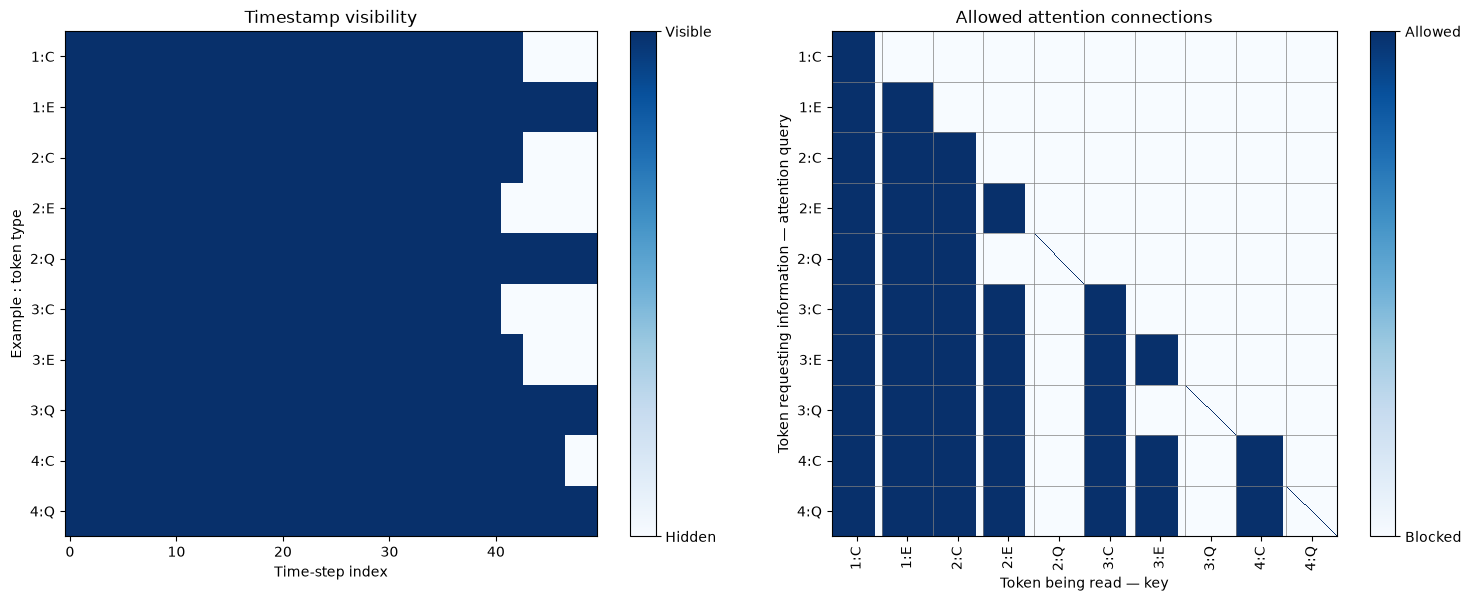

In [28]:
preview_dataset = OUExamplesDataset(
    train_data,
    mask_inputs=True,
    seed=123,
    fixed_masks=True,
)

sample = preview_dataset[0]

visible = ~sample["key_padding_mask"]

# Combine the structural attention mask and missing-observation mask.
combined_blocked = (
    preview_dataset.attention_mask
    | sample["key_padding_mask"][None, :]
)

type_names = {0: "C", 1: "E", 2: "Q"}

block_labels = [
    f"{example_id + 1}:{type_names[token_type]}"
    for example_id, token_type in preview_dataset.blocks
]

visibility_image = visible.reshape(
    len(block_labels), preview_dataset.n_steps
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

image = axes[0].imshow(
    visibility_image.float().numpy(),
    aspect="auto",
    cmap="Blues",
    vmin=0,
    vmax=1,
    interpolation="nearest",
)
axes[0].set_yticks(range(len(block_labels)))
axes[0].set_yticklabels(block_labels)
axes[0].set_xlabel("Time-step index")
axes[0].set_ylabel("Example : token type")
axes[0].set_title("Timestamp visibility")

colorbar = fig.colorbar(image, ax=axes[0], ticks=[0, 1])
colorbar.ax.set_yticklabels(["Hidden", "Visible"])

image = axes[1].imshow(
    (~combined_blocked).float().numpy(),
    cmap="Blues",
    vmin=0,
    vmax=1,
    interpolation="nearest",
)

centers = [
    i * preview_dataset.n_steps
    + (preview_dataset.n_steps - 1) / 2
    for i in range(len(block_labels))
]

axes[1].set_xticks(centers)
axes[1].set_xticklabels(block_labels, rotation=90)
axes[1].set_yticks(centers)
axes[1].set_yticklabels(block_labels)

for boundary in range(1, len(block_labels)):
    position = boundary * preview_dataset.n_steps - 0.5
    axes[1].axhline(position, color="gray", linewidth=0.5)
    axes[1].axvline(position, color="gray", linewidth=0.5)

axes[1].set_xlabel("Token being read — key")
axes[1].set_ylabel("Token requesting information — attention query")
axes[1].set_title("Allowed attention connections")

colorbar = fig.colorbar(image, ax=axes[1], ticks=[0, 1])
colorbar.ax.set_yticklabels(["Blocked", "Allowed"])

plt.tight_layout()
plt.show()

Explaing the mask

| Prediction block | What it can read | Answer it must predict |
|---|---|---|
| `2:Q` | Worked example 1 and condition `2:C` | Correction for trajectory 2 |
| `3:Q` | Worked examples 1–2 and condition `3:C` | Correction for trajectory 3 |
| `4:Q` | Worked examples 1–3 and condition `4:C` | Correction for trajectory 4 |

The answer for trajectory 2 is present in 2:E, but 2:Q must predict it. Reading that block would let the model copy the answer.
However, 3:Q can read 2:E: when solving trajectory 3, trajectory 2 is a worked demonstration.
So the same correction has two roles:
- For Q2: E2 is the answer being predicted → blocked.
- For Q3 and Q4: E2 is a demonstration answer → allowed.

Why prediction blocks contain thin diagonal lines

Q2 at time t10 can read:
    Its own time/noise coordinates
    Available C2 observations
    The earlier demonstration C1/E1

It cannot read:
    Q2 at t11
    The answer E2
    Later trajectory examples

Consequently, all 50 corrections can be predicted in parallel. We are correcting an already available coarse trajectory, so each prediction may read available coarse observations across that trajectory—not just earlier timestamps.

We’ll follow the same overall structure as IconGPTModel, translated into PyTorch and simplified for our caption-free OU example.

The forward pass in [models_lm.py (line 84)](/Users/noorainnoorani/Documents/UMD-PhD/FMint_SDE_Coloured_Noise/models_lm.py:84) maps naturally to our notebook:
| `IconGPTModel` component | Our `FMintSDE` equivalent |
|---|---|
| `build_data_sequence` | Tokens already assembled by `OUExamplesDataset` |
| `pre_projection` | `torch.nn.Linear(3, model_dim)` |
| `func_pos_embedding` | Learned embedding identifying the trajectory and token type |
| `SelfAttnTransformer` | PyTorch self-attention blocks using our custom mask |
| `post_projection` | `torch.nn.Linear(model_dim, 1)` |
| Output selection | `loss_mask` for training; `query_mask` for evaluation |

The model’s computation will be:

Numerical tokens: [time, noise, value]
                    ↓
             Linear projection
                    +
     Learned trajectory/type embedding
                    ↓
       Masked self-attention blocks
                    ↓
         Scalar correction output
                    ↓
       Select prediction positions

Each token has three features:
Condition:  [time, noise increment, coarse state]
Correction: [time, noise increment, known correction]
Prediction: [time, noise increment, 0]



In [29]:
class FMintSDE(torch.nn.Module):
    def __init__(
        self,
        num_demos,
        n_steps,
        model_dim=64,
        num_heads=4,
        num_layers=2,
        feedforward_dim=128,
        dropout=0.0,
    ):
        super().__init__()

        if model_dim % num_heads != 0:
            raise ValueError("model_dim must be divisible by num_heads.")

        self.num_demos = num_demos
        self.n_steps = n_steps

        # 1. Numerical features → model embeddings.
        self.pre_projection = torch.nn.Linear(3, model_dim)

        # 2. Learn an identity for every trajectory/token-type pair.
        num_token_ids = 3 * (num_demos + 1)
        self.func_pos_embedding = torch.nn.Embedding(
            num_token_ids, model_dim
        )

        # 3. Self-attention and feedforward blocks. - called encoder layer in PyTorch but still just self attention, not an encoder-decoder architecture
        layer = torch.nn.TransformerEncoderLayer(
            d_model=model_dim,
            nhead=num_heads,
            dim_feedforward=feedforward_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=False,
        )

        self.transformer = torch.nn.TransformerEncoder(
            encoder_layer=layer,
            num_layers=num_layers,
            enable_nested_tensor=False,
        )

        # Give the cloned layers distinct initial matrix weights.
        for transformer_layer in self.transformer.layers:
            for parameter in transformer_layer.parameters():
                if parameter.dim() > 1:
                    torch.nn.init.xavier_uniform_(parameter)

        # 4. Model embeddings → scalar corrections.
        self.post_projection = torch.nn.Linear(model_dim, 1)

        # 5. Construct the fixed layout and masks.
        _, example_ids, token_types, attention_mask = (
            build_attention_layout(num_demos, n_steps)
        )

        self.register_buffer("attention_mask", attention_mask)

        self.register_buffer(
            "loss_mask",
            token_types == 2,
        )

        self.register_buffer(
            "query_mask",
            (token_types == 2) & (example_ids == num_demos),
        )

    def forward(
        self,
        tokens,
        example_ids,
        token_types,
        key_padding_mask=None,
    ):
        """
        tokens:           (batch, sequence_length, 3)
        example_ids:      (batch, sequence_length)
        token_types:      (batch, sequence_length)
        key_padding_mask: (batch, sequence_length), True = hidden

        Returns:
            (batch, sequence_length, 1)
        """
        if tokens.ndim != 3 or tokens.shape[-1] != 3:
            raise ValueError("tokens must have shape (batch, sequence, 3).")

        if tokens.shape[1] != self.attention_mask.shape[0]:
            raise ValueError("Token length does not match the model's layout.")

        # Embed the numerical content.
        numerical_embedding = self.pre_projection(tokens)

        # Embed the trajectory identity and token category.
        token_ids = (3 * example_ids + token_types).long()
        identity_embedding = self.func_pos_embedding(token_ids)

        embeddings = numerical_embedding + identity_embedding

        # Both masks use True to mean blocked.
        hidden = self.transformer(
            embeddings,
            mask=self.attention_mask,
            src_key_padding_mask=key_padding_mask,
            is_causal=False,
        )

        return self.post_projection(hidden)

    def predict_correction(
        self,
        tokens,
        example_ids,
        token_types,
        key_padding_mask=None,
    ):
        """Return corrections for the final query trajectory."""
        predictions = self(
            tokens,
            example_ids,
            token_types,
            key_padding_mask,
        )

        return predictions[:, self.query_mask]

In [30]:
"""
class FMintSDE:
    def __init__(self, model_config, data_config, *, seed=0):
        ...

    @classmethod
    def from_checkpoint(cls, path, **kwargs):
        ...

    def predict_correction(self, coarse, *, times, noise,
                           demonstrations=None, caption=None):
        ...

    def predict(self, coarse, *, times, noise,
                demonstrations=None, caption=None):
        # Return coarse + predicted correction.
        ...

    def rollout(self, initial_state, coarse_solver, noise,
                *, steps, window, demonstrations=None, caption=None):
        ...

    def fit(self, train_data, validation_data=None, *, steps):
        ...

    def finetune(self, train_data, *, steps):
        ...

    def evaluate(self, dataset):
        ...

    def save(self, path):
        ...
"""

'\nclass FMintSDE:\n    def __init__(self, model_config, data_config, *, seed=0):\n        ...\n\n    @classmethod\n    def from_checkpoint(cls, path, **kwargs):\n        ...\n\n    def predict_correction(self, coarse, *, times, noise,\n                           demonstrations=None, caption=None):\n        ...\n\n    def predict(self, coarse, *, times, noise,\n                demonstrations=None, caption=None):\n        # Return coarse + predicted correction.\n        ...\n\n    def rollout(self, initial_state, coarse_solver, noise,\n                *, steps, window, demonstrations=None, caption=None):\n        ...\n\n    def fit(self, train_data, validation_data=None, *, steps):\n        ...\n\n    def finetune(self, train_data, *, steps):\n        ...\n\n    def evaluate(self, dataset):\n        ...\n\n    def save(self, path):\n        ...\n'

In [31]:
def masked_mse(predictions, targets, mask):
    error = predictions[:, mask] - targets[:, mask]
    return error.square().mean()

In [32]:
import math


class WarmupCosineDecayScheduler(
    torch.optim.lr_scheduler.LRScheduler
):
    def __init__(self, optimizer, warmup, max_iters):
        if not 1 <= warmup < max_iters:
            raise ValueError("Require 1 <= warmup < max_iters.")

        self.warmup = warmup
        self.max_num_iters = max_iters

        super().__init__(optimizer)

    def get_lr(self):
        factor = self.get_lr_factor(self.last_epoch)
        return [base_lr * factor for base_lr in self.base_lrs]

    def get_lr_factor(self, epoch):
        # Count training updates from 1 and stop at the final step.
        step = min(epoch + 1, self.max_num_iters)

        if step <= self.warmup:
            return step / self.warmup

        progress = (
            (step - self.warmup)
            / (self.max_num_iters - self.warmup)
        )

        return 0.5 * (1.0 + math.cos(math.pi * progress))

In [39]:
class FMintTrainer:
    def __init__(
        self,
        model,
        device,
        learning_rate=1e-3,
        grad_clip=1.0,
    ):
        self.device = torch.device(device)
        self.model = model.to(self.device)
        self.learning_rate = learning_rate
        self.grad_clip = grad_clip

    def _move_batch(self, batch):
        return {
            name: tensor.to(self.device)
            for name, tensor in batch.items()
        }

    def _forward(self, batch):
        # Targets are used only when computing the loss.
        return self.model(
            tokens=batch["tokens"],
            example_ids=batch["example_ids"],
            token_types=batch["token_types"],
            key_padding_mask=batch["key_padding_mask"],
        )

    @torch.no_grad()
    def evaluate(self, loader):
        self.model.eval()

        squared_error = 0.0
        coarse_squared_error = 0.0
        count = 0

        for batch in loader:
            batch = self._move_batch(batch)
            predictions = self._forward(batch)

            # Evaluate only the final query trajectory.
            predicted = predictions[:, self.model.query_mask]
            expected = batch["targets"][:, self.model.query_mask]

            squared_error += (
                (predicted - expected).square().sum().item()
            )

            # The coarse solver predicts a correction of zero.
            coarse_squared_error += expected.square().sum().item()

            count += expected.numel()

        if count == 0:
            raise ValueError("The evaluation loader is empty.")

        return {
            "mse": squared_error / count,
            "coarse_mse": coarse_squared_error / count,
        }

    def fit(
        self,
        train_loader,
        val_loader,
        *,
        steps,
        warmup_steps=200,
        validate_every=100,
    ):
        if (
            steps < 1
            or validate_every < 1
            or len(train_loader) == 0
        ):
            raise ValueError(
                "Use positive steps/interval and a nonempty training loader."
            )

        optimizer = torch.optim.Adam(
            self.model.parameters(),
            lr=self.learning_rate,
        )

        scheduler = WarmupCosineDecayScheduler(
            optimizer,
            warmup=warmup_steps,
            max_iters=steps,
        )

        # Measure validation performance before training.
        initial = self.evaluate(val_loader)

        history = {
            "train_step": [],
            "train_mse": [],
            "validation_step": [0],
            "validation_mse": [initial["mse"]],
            "coarse_mse": initial["coarse_mse"],
        }

        history["learning_rate"] = []

        best_mse = initial["mse"]
        best_step = 0

        # Store an independent copy of the best weights.
        best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in self.model.state_dict().items()
        }

        print(
            f"Before training | validation MSE {initial['mse']:.3e} | "
            f"coarse MSE {initial['coarse_mse']:.3e}"
        )

        batches = iter(train_loader)

        for step in range(1, steps + 1):
            # Start another pass when all batches have been used.
            try:
                batch = next(batches)
            except StopIteration:
                batches = iter(train_loader)
                batch = next(batches)

            self.model.train()
            batch = self._move_batch(batch)

            # 1. Clear gradients from the previous update.
            optimizer.zero_grad(set_to_none=True)

            # 2. Predict corrections and compute the masked loss.
            predictions = self._forward(batch)

            loss = masked_mse(
                predictions,
                batch["targets"],
                self.model.loss_mask,
            )

            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    f"Non-finite training loss at step {step}."
                )

            # 3. Compute gradients.
            loss.backward()

            # 4. Limit unusually large gradients.
            torch.nn.utils.clip_grad_norm_(
                self.model.parameters(),
                self.grad_clip,
                error_if_nonfinite=True,
            )

            # Record the learning rate used for this update.
            current_lr = optimizer.param_groups[0]["lr"]

            # 5. Update model parameters.
            optimizer.step()

            # Set the learning rate for the next update.
            scheduler.step()

            history["train_step"].append(step)
            history["train_mse"].append(loss.item())
            history["learning_rate"].append(current_lr)

            # Periodically evaluate the full validation dataset.
            if (
                step == 1
                or step % validate_every == 0
                or step == steps
            ):
                metrics = self.evaluate(val_loader)

                history["validation_step"].append(step)
                history["validation_mse"].append(metrics["mse"])

                if metrics["mse"] < best_mse:
                    best_mse = metrics["mse"]
                    best_step = step

                    best_state = {
                        name: tensor.detach().cpu().clone()
                        for name, tensor
                        in self.model.state_dict().items()
                    }

                print(
                    f"Step {step:5d} | "
                    f"train MSE {loss.item():.3e} | "
                    f"validation MSE {metrics['mse']:.3e}"
                )

        # Use the model selected by validation.
        self.model.load_state_dict(best_state)
        self.model.eval()

        history["best_step"] = best_step

        print(
            f"Restored step {best_step}, "
            f"validation MSE {best_mse:.3e}"
        )

        return history

In [41]:
warmup_steps = 200

In [42]:
torch.manual_seed(seed)

model = FMintSDE(
    num_demos=train_dataset.num_demos,
    n_steps=train_dataset.n_steps,
    model_dim=model_dim,
    num_heads=num_heads,
    num_layers=num_layers,
    feedforward_dim=feedforward_dim,
)

trainer = FMintTrainer(
    model,
    device=device,
    learning_rate=learning_rate,
    grad_clip=1.0,
)

history = trainer.fit(
    train_loader,
    val_loader,
    steps=training_steps,
    warmup_steps=warmup_steps,
    validate_every=100,
)

Before training | validation MSE 7.030e-01 | coarse MSE 4.321e-01
Step     1 | train MSE 7.146e-01 | validation MSE 6.921e-01
Step   100 | train MSE 5.891e-01 | validation MSE 3.638e-01
Step   200 | train MSE 7.626e-01 | validation MSE 3.521e-01
Step   300 | train MSE 4.941e-01 | validation MSE 3.739e-01
Step   400 | train MSE 1.213e+00 | validation MSE 3.628e-01
Step   500 | train MSE 4.631e-01 | validation MSE 3.620e-01
Step   600 | train MSE 3.127e-01 | validation MSE 3.299e-01
Step   700 | train MSE 6.374e-01 | validation MSE 3.161e-01
Step   800 | train MSE 4.741e-01 | validation MSE 2.997e-01
Step   900 | train MSE 4.249e-01 | validation MSE 2.807e-01
Step  1000 | train MSE 5.300e-01 | validation MSE 2.925e-01
Step  1100 | train MSE 5.460e-01 | validation MSE 2.734e-01
Step  1200 | train MSE 3.306e-01 | validation MSE 2.706e-01
Step  1300 | train MSE 3.022e-01 | validation MSE 2.577e-01
Step  1400 | train MSE 7.407e-01 | validation MSE 2.589e-01
Step  1500 | train MSE 2.771e-01 |

In [50]:
trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {trainable_parameters:,}")

Trainable parameters: 68,033


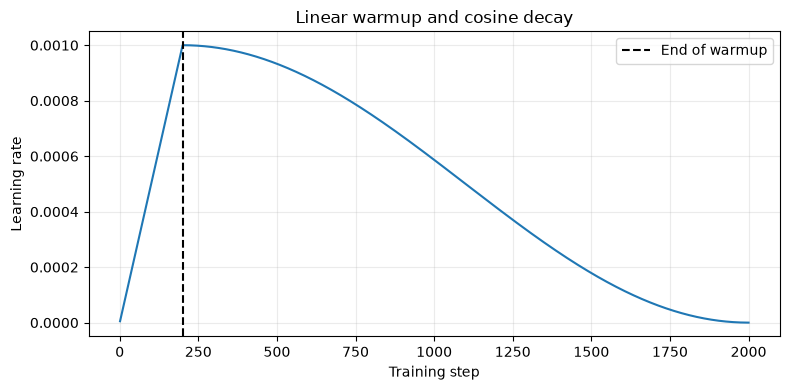

In [43]:
plt.figure(figsize=(8, 4))

plt.plot(
    history["train_step"],
    history["learning_rate"],
)

plt.axvline(
    warmup_steps,
    color="black",
    linestyle="--",
    label="End of warmup",
)

plt.xlabel("Training step")
plt.ylabel("Learning rate")
plt.title("Linear warmup and cosine decay")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

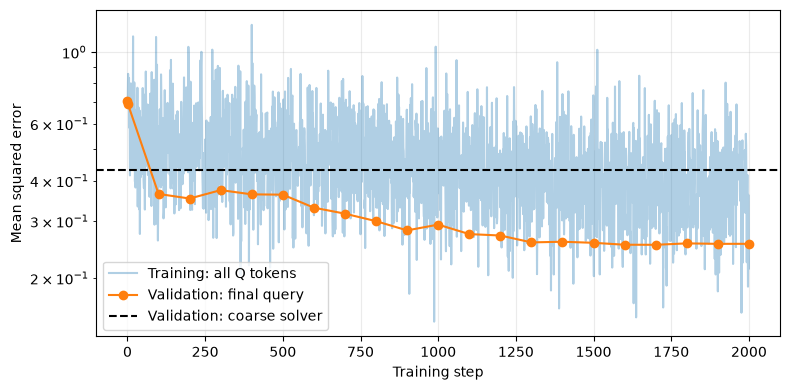

In [44]:
plt.figure(figsize=(8, 4))

plt.semilogy(
    history["train_step"],
    history["train_mse"],
    alpha=0.35,
    label="Training: all Q tokens",
)

plt.semilogy(
    history["validation_step"],
    history["validation_mse"],
    marker="o",
    label="Validation: final query",
)

plt.axhline(
    history["coarse_mse"],
    color="black",
    linestyle="--",
    label="Validation: coarse solver",
)

plt.xlabel("Training step")
plt.ylabel("Mean squared error")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [45]:
test_metrics = trainer.evaluate(test_loader)

print(f"Coarse test MSE:    {test_metrics['coarse_mse']:.3e}")
print(f"FMint-SDE test MSE: {test_metrics['mse']:.3e}")

if test_metrics["coarse_mse"] > 0:
    reduction = 100 * (
        1 - test_metrics["mse"] / test_metrics["coarse_mse"]
    )
    print(f"Test MSE reduction: {reduction:.1f}%")

Coarse test MSE:    5.595e-01
FMint-SDE test MSE: 4.361e-01
Test MSE reduction: 22.1%


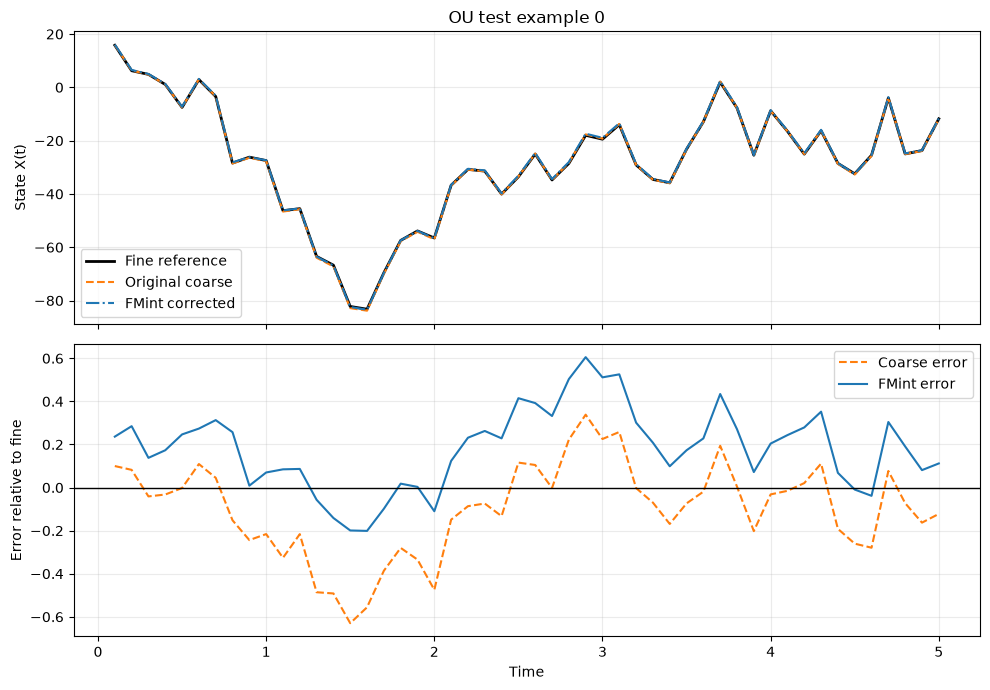

Sample coarse MSE: 5.578e-02
Sample FMint MSE:  6.735e-02


In [47]:
# Change this index to inspect another test example.
example_index = 0
sample = test_dataset[example_index]

# Add a batch dimension and move inputs to the model's device.
model_inputs = {
    name: sample[name].unsqueeze(0).to(trainer.device)
    for name in (
        "tokens",
        "example_ids",
        "token_types",
        "key_padding_mask",
    )
}

# Use the trained model selected by validation.
trained_model = trainer.model
trained_model.eval()

with torch.no_grad():
    predicted_correction = trained_model.predict_correction(
        **model_inputs
    )[0, :, 0].cpu()

# Retrieve the matching query trajectory.
query_inputs = test_dataset.data["inputs"]["query_inputs"][
    example_index
].cpu()

times = query_inputs[:, 0]
coarse = query_inputs[:, 2]

true_correction = test_dataset.data["targets"][
    example_index, :, 0
].cpu()

fine_reference = coarse + true_correction
fmint_corrected = coarse + predicted_correction

# Plot trajectories and their errors.
fig, axes = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True
)

axes[0].plot(
    times, fine_reference,
    color="black", linewidth=2,
    label="Fine reference",
)
axes[0].plot(
    times, coarse,
    color="tab:orange", linestyle="--",
    label="Original coarse",
)
axes[0].plot(
    times, fmint_corrected,
    color="tab:blue", linestyle="-.",
    label="FMint corrected",
)

axes[0].set_title(f"OU test example {example_index}")
axes[0].set_ylabel("State X(t)")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    times, coarse - fine_reference,
    color="tab:orange", linestyle="--",
    label="Coarse error",
)
axes[1].plot(
    times, fmint_corrected - fine_reference,
    color="tab:blue",
    label="FMint error",
)

axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Error relative to fine")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Compare errors for this particular trajectory.
coarse_mse = (coarse - fine_reference).square().mean().item()
fmint_mse = (
    fmint_corrected - fine_reference
).square().mean().item()

print(f"Sample coarse MSE: {coarse_mse:.3e}")
print(f"Sample FMint MSE:  {fmint_mse:.3e}")

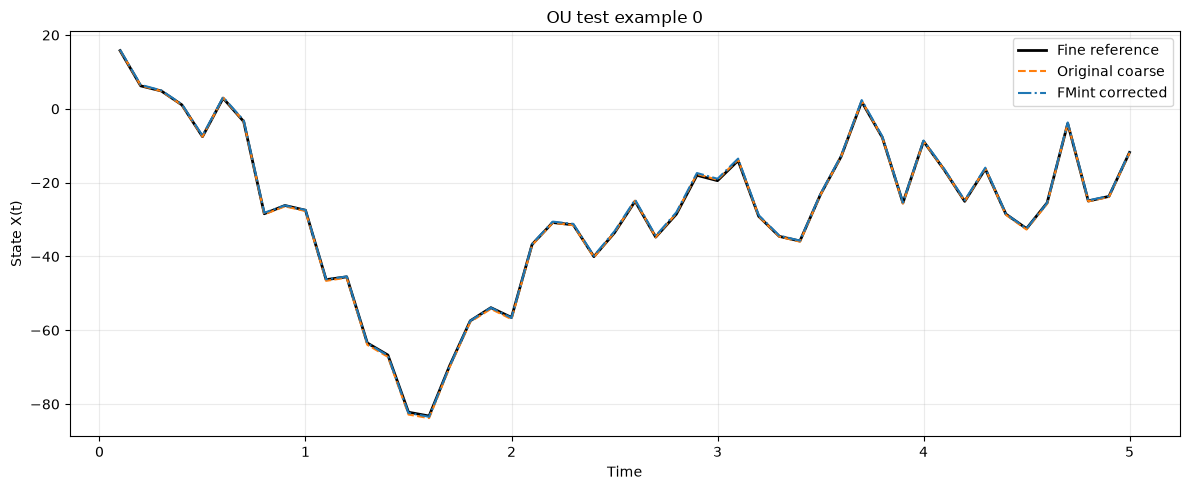

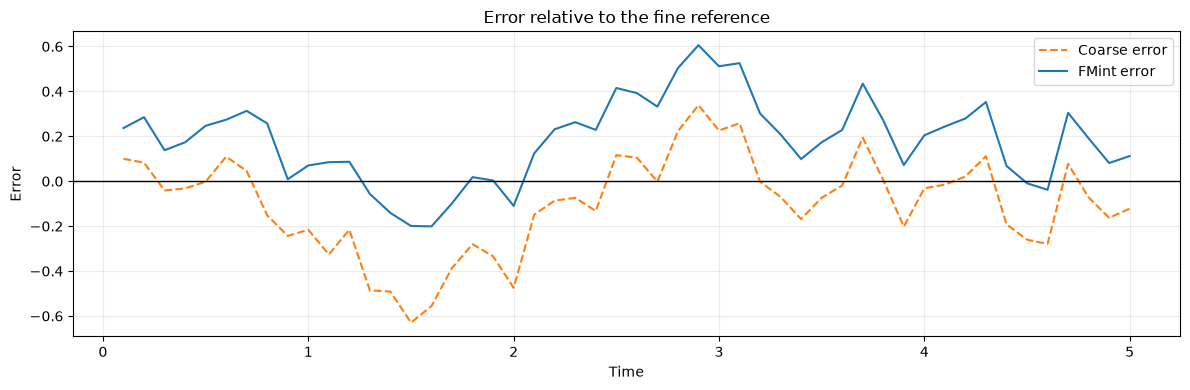

In [48]:
# Figure 1: OU state trajectories.
plt.figure(figsize=(12, 5))

plt.plot(
    times, fine_reference,
    color="black", linewidth=2,
    label="Fine reference",
)
plt.plot(
    times, coarse,
    color="tab:orange", linestyle="--",
    label="Original coarse",
)
plt.plot(
    times, fmint_corrected,
    color="tab:blue", linestyle="-.",
    label="FMint corrected",
)

plt.title(f"OU test example {example_index}")
plt.xlabel("Time")
plt.ylabel("State X(t)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# Figure 2: Errors relative to the fine reference.
plt.figure(figsize=(12, 4))

plt.plot(
    times, coarse - fine_reference,
    color="tab:orange", linestyle="--",
    label="Coarse error",
)
plt.plot(
    times, fmint_corrected - fine_reference,
    color="tab:blue",
    label="FMint error",
)

plt.axhline(0, color="black", linewidth=1)
plt.title("Error relative to the fine reference")
plt.xlabel("Time")
plt.ylabel("Error")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()